# 01 - Explore the shopping sessions

This notebook explains the data: what each column contains, how often sessions end in a purchase, and which patterns are worth investigating. The other notebooks cover preparation, training and evaluation.

See [README.md](README.md) for setup instructions and the data source.

## 1. Load the data

Import the libraries and read the CSV from this folder. Show a few rows to check that it loaded correctly.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

CSV_PATH = Path("online_shoppers_intention.csv")

sessions = pd.read_csv(CSV_PATH)
print(f"Loaded {CSV_PATH.resolve()}")
print(f"Shape: {sessions.shape[0]:,} rows × {sessions.shape[1]} columns")
display(sessions.head())

Loaded C:\code projects\ml-cw2\online_shoppers_intention.csv
Shape: 12,330 rows × 18 columns


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2. Understand the columns

Check each column's type, number of filled values and number of distinct values. `Revenue` is the outcome we want to predict.

In [2]:
display(pd.DataFrame({
    "dtype": sessions.dtypes.astype(str),
    "non_null": sessions.notna().sum(),
    "unique_values": sessions.nunique(dropna=False),
}))

,dtype,non_null,unique_values
Administrative,int64,12330,27
Administrative_Duration,float64,12330,3335
Informational,int64,12330,17
Informational_Duration,float64,12330,1258
ProductRelated,int64,12330,311
ProductRelated_Duration,float64,12330,9551
BounceRates,float64,12330,1872
ExitRates,float64,12330,4777
PageValues,float64,12330,2704
SpecialDay,float64,12330,6


## 3. Check missing values and duplicate rows

Look for empty values, placeholder text and repeated rows. Matching values can come from different shopping sessions, so duplicate counts need interpretation.

In [3]:
missing = pd.DataFrame({
    "missing_count": sessions.isna().sum(),
    "missing_pct": (sessions.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)
display(missing)
print("Total missing cells:", int(sessions.isna().sum().sum()))
print("Entire-row duplicates:", int(sessions.duplicated().sum()))
print("Duplicates across predictors only:", int(sessions.drop(columns="Revenue").duplicated().sum()))

# Blank / placeholder strings can be missed by isna().
text_columns = sessions.select_dtypes(include=["object", "string"]).columns
placeholder_tokens = {"", "?", "na", "n/a", "null", "none", "unknown"}
placeholder_counts = {}
for column in text_columns:
    text_values = sessions[column].astype('string').str.strip().str.lower()
    placeholder_counts[column] = int(text_values.isin(placeholder_tokens).sum())
display(pd.Series(placeholder_counts, name="blank_or_placeholder_count").to_frame())

,missing_count,missing_pct
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


Total missing cells: 0
Entire-row duplicates: 125
Duplicates across predictors only: 125


,blank_or_placeholder_count
Month,0
VisitorType,0


## 4. Count purchases and non-purchases

Convert Revenue to 0 for no purchase and 1 for purchase. Compare the class counts. Purchases are less common, so accuracy alone can hide poor purchase detection.

In [4]:
purchase_labels = sessions["Revenue"].astype(int)
print("Target distribution:")
class_table = pd.DataFrame({"count": purchase_labels.value_counts().sort_index(),
                            "percentage": (purchase_labels.value_counts(normalize=True).sort_index()*100).round(2)})
class_table.index = ["No purchase (0)", "Purchase (1)"]
display(class_table)

Target distribution:


,count,percentage
No purchase (0),10422,84.53
Purchase (1),1908,15.47


The chart shows how many sessions purchased and how many did not.

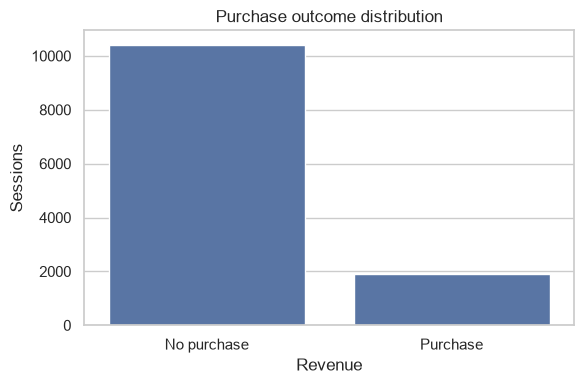

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=purchase_labels.map({0:"No purchase", 1:"Purchase"}), order=["No purchase", "Purchase"], ax=ax)
ax.set(title="Purchase outcome distribution", xlabel="Revenue", ylabel="Sessions")
plt.tight_layout(); plt.show()

## 5. Look at numeric values

Show typical values and ranges, then plot the distributions. Category codes such as Browser and Region are labels, so they are left out of continuous-value plots.

In [6]:
numeric_columns = sessions.select_dtypes(include=np.number).columns.tolist()
print(f"Numeric columns ({len(numeric_columns)}):", numeric_columns)
display(sessions[numeric_columns].describe().T.round(2))

# Exclude integer-coded nominal identifiers from continuous distribution plots.
nominal_code_columns = {"OperatingSystems", "Browser", "Region", "TrafficType"}
continuous_columns = [c for c in numeric_columns if c not in nominal_code_columns]

Numeric columns (14): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


Counts and durations have long right tails. Numeric category codes are left out of these histograms.

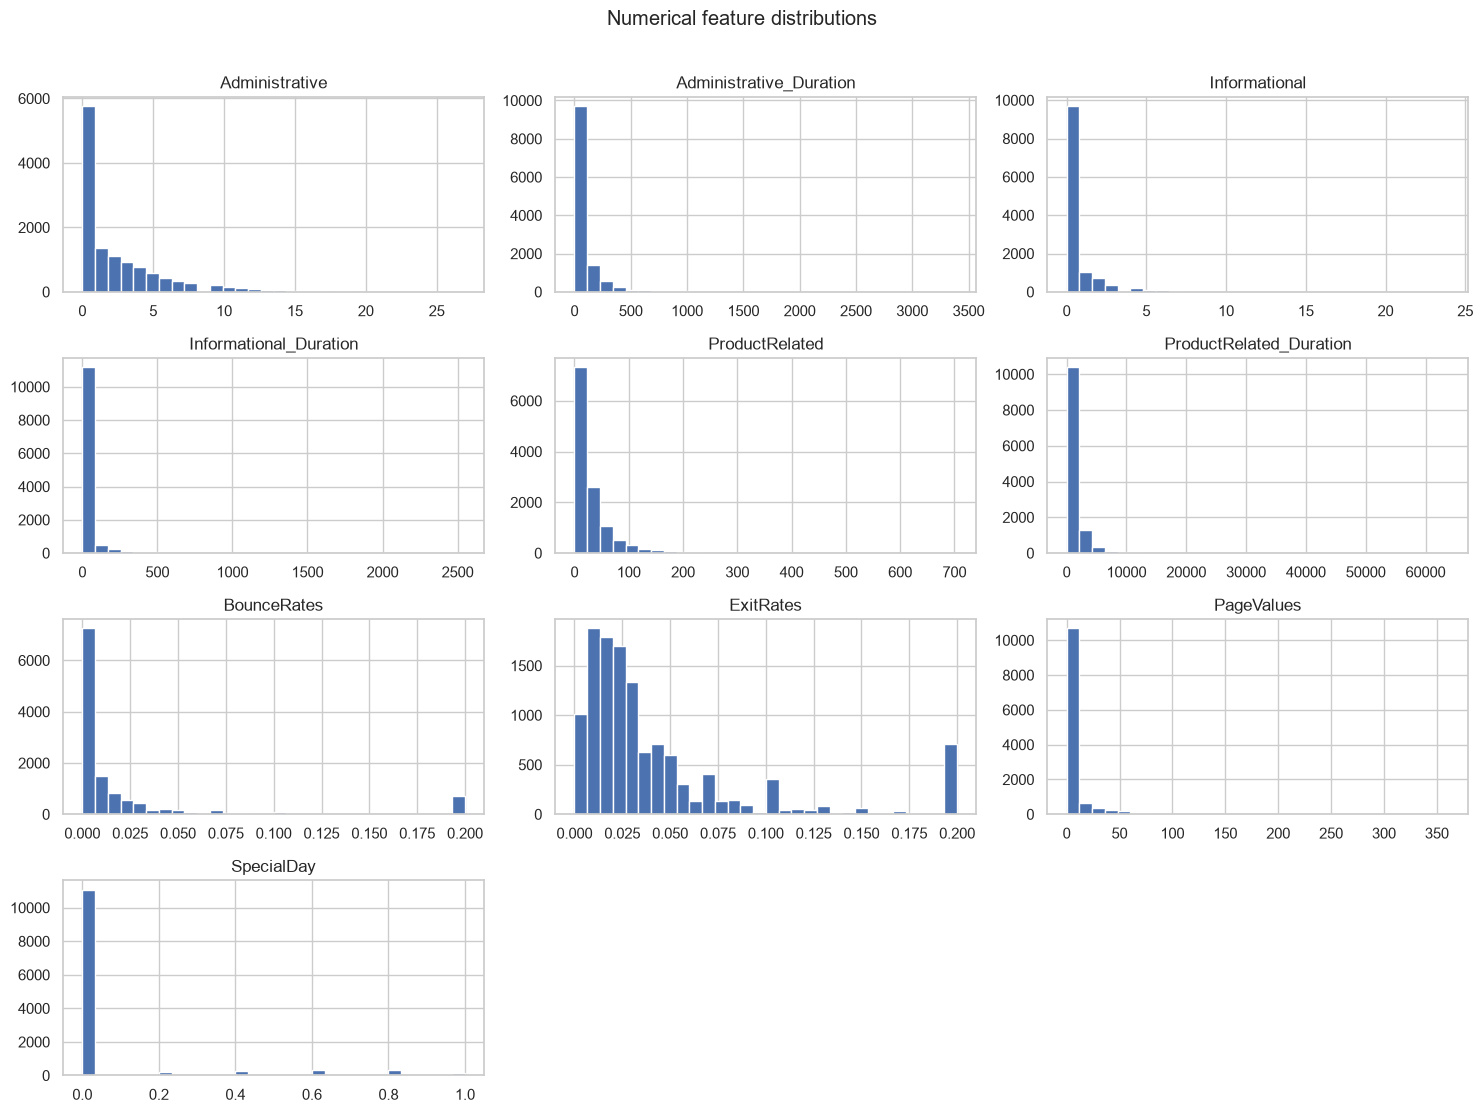

In [7]:
sessions[continuous_columns].hist(bins=30, figsize=(15, 11), layout=(int(np.ceil(len(continuous_columns)/3)), 3))
plt.suptitle("Numerical feature distributions", y=1.01)
plt.tight_layout(); plt.show()

Skewness measures how uneven a distribution is. Larger positive values mean a longer right tail.

In [8]:
skewness = sessions[continuous_columns].skew().sort_values(key=lambda feature_values:feature_values.abs(), ascending=False)
display(skewness.rename("skewness").round(2).to_frame())

,skewness
Informational_Duration,7.58
ProductRelated_Duration,7.26
PageValues,6.38
Administrative_Duration,5.62
ProductRelated,4.34
Informational,4.04
SpecialDay,3.30
BounceRates,2.95
ExitRates,2.15
Administrative,1.96


## 6. Inspect unusually large values

The interquartile range (IQR) describes the middle half of the values. Flag values far beyond it for inspection. Long browsing sessions can be valid, so these flags do not automatically remove rows.

In [9]:
outlier_rows = []
for column in continuous_columns:
    feature_values = sessions[column]
    q1, q3 = feature_values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_flagged = int(((feature_values < lower) | (feature_values > upper)).sum())
    outlier_rows.append({"feature": column, "lower_fence": lower, "upper_fence": upper,
                     "flagged": n_flagged, "flagged_pct": round(100 * n_flagged / len(feature_values), 2)})
display(pd.DataFrame(outlier_rows).sort_values("flagged", ascending=False).round(2))

,feature,lower_fence,upper_fence,flagged,flagged_pct
8,PageValues,0.00,0.00,2730,22.14
2,Informational,0.00,0.00,2631,21.34
3,Informational_Duration,0.00,0.00,2405,19.51
6,BounceRates,-0.03,0.04,1551,12.58
9,SpecialDay,0.00,0.00,1251,10.15
1,Administrative_Duration,-139.88,233.14,1172,9.51
7,ExitRates,-0.04,0.10,1099,8.91
4,ProductRelated,-39.50,84.50,987,8.00
5,ProductRelated_Duration,-1735.89,3384.19,961,7.79
0,Administrative,-6.00,10.00,404,3.28


Boxplots show the long tails. These flags alone do not show that a session is wrong.

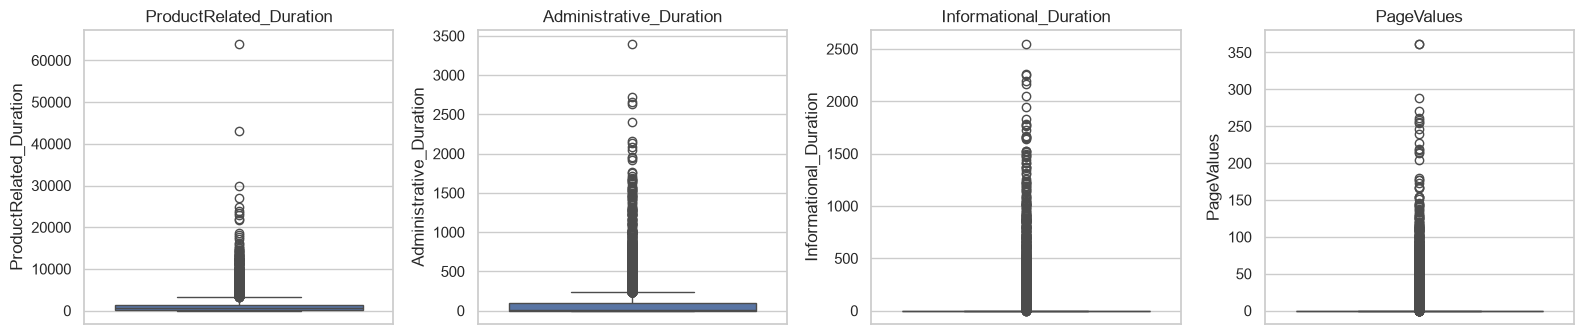

In [10]:
selected = ["ProductRelated_Duration", "Administrative_Duration", "Informational_Duration", "PageValues"]
fig, axes = plt.subplots(1, len(selected), figsize=(4*len(selected), 3.5), squeeze=False)
for ax, column in zip(axes.ravel(), selected):
    sns.boxplot(y=sessions[column], ax=ax)
    ax.set_title(column)
plt.tight_layout(); plt.show()

## 7. Compare numeric relationships

The heatmap shows which numeric values tend to rise or fall together. The table shows their association with purchases. Correlation describes a pattern; it does not establish its cause.

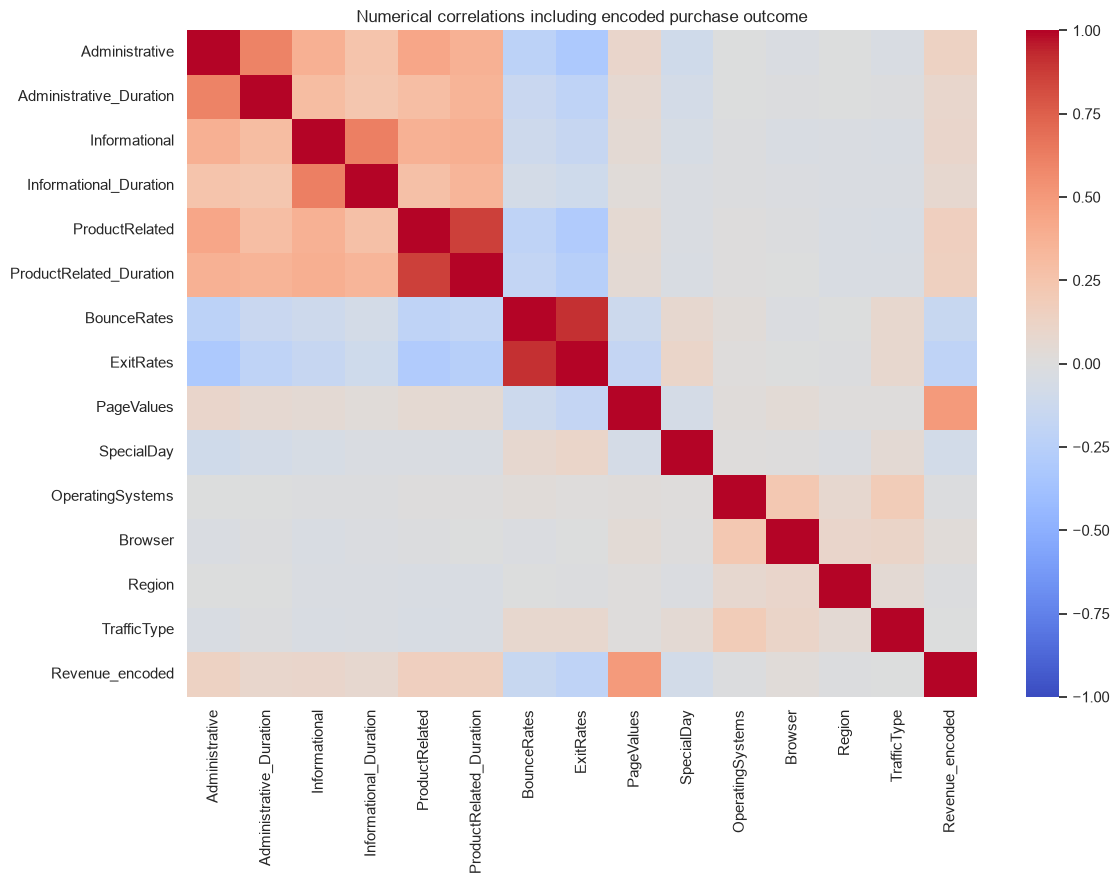

,correlation_with_revenue
PageValues,0.493
ExitRates,-0.207
ProductRelated,0.159
ProductRelated_Duration,0.152
BounceRates,-0.151
Administrative,0.139
Informational,0.095
Administrative_Duration,0.094
SpecialDay,-0.082
Informational_Duration,0.070


In [11]:
correlation_data = sessions[numeric_columns].copy()
correlation_data["Revenue_encoded"] = purchase_labels
correlations = correlation_data.corr()
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(correlations, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Numerical correlations including encoded purchase outcome")
plt.tight_layout(); plt.show()
display(correlations["Revenue_encoded"].drop("Revenue_encoded").sort_values(key=lambda feature_values:feature_values.abs(), ascending=False).rename("correlation_with_revenue").round(3).to_frame())

## 8. Compare purchase rates across categories

For each category, show how many sessions it contains and what percentage purchased. Small groups can have unstable percentages.

In [12]:
categorical_columns = ["Month", "VisitorType", "Weekend", "OperatingSystems", "Browser", "Region", "TrafficType", "SpecialDay"]
for column in categorical_columns:
    summary = (pd.DataFrame({column:sessions[column], "Revenue_encoded":purchase_labels})
               .groupby(column, dropna=False)["Revenue_encoded"]
               .agg(sessions="count", conversion_rate="mean")
               .sort_values("sessions", ascending=False))
    summary["conversion_rate_pct"] = (100 * summary["conversion_rate"]).round(2)
    print(f"\n{column}")
    display(summary[["sessions", "conversion_rate_pct"]].head(20))


Month


,sessions,conversion_rate_pct
Month,,
May,3364,10.85
Nov,2998,25.35
Mar,1907,10.07
Dec,1727,12.51
Oct,549,20.95
Sep,448,19.20
Aug,433,17.55
Jul,432,15.28
June,288,10.07



VisitorType


,sessions,conversion_rate_pct
VisitorType,,
Returning_Visitor,10551,13.93
New_Visitor,1694,24.91
Other,85,18.82



Weekend


,sessions,conversion_rate_pct
Weekend,,
False,9462,14.89
True,2868,17.40


... (6 outputs left out)


TrafficType


,sessions,conversion_rate_pct
TrafficType,,
2,3913,21.65
1,2451,10.69
3,2052,8.77
4,1069,15.43
13,738,5.83
10,450,20.00
6,444,11.94
8,343,27.70
5,260,21.54



SpecialDay


,sessions,conversion_rate_pct
SpecialDay,,
0.0,11079,16.53
0.6,351,8.26
0.8,325,3.38
0.4,243,5.35
0.2,178,7.87
1.0,154,6.49


The following charts show the same purchase rates for month, visitor type and weekend.

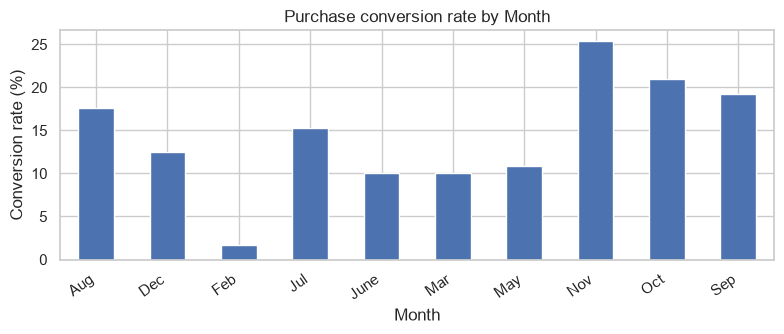

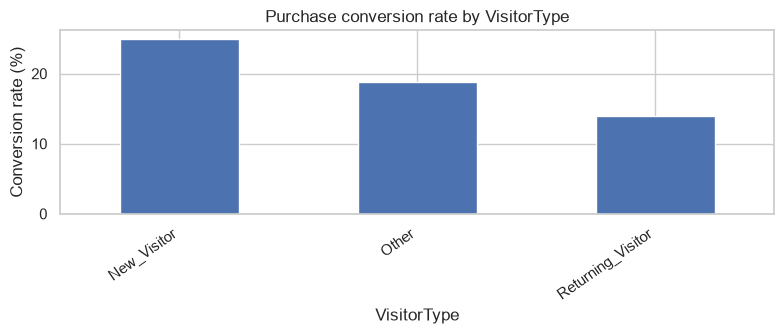

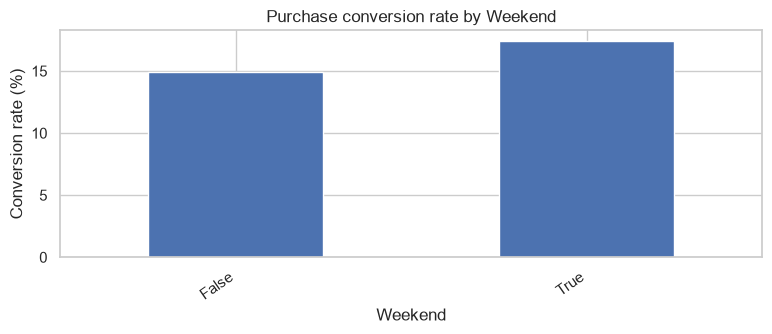

In [13]:
for column in ["Month", "VisitorType", "Weekend"]:
    rates = (pd.DataFrame({column:sessions[column], "Revenue_encoded":purchase_labels})
             .groupby(column, dropna=False)["Revenue_encoded"].mean().mul(100))
    fig, ax = plt.subplots(figsize=(8, 3.5))
    rates.plot(kind="bar", ax=ax)
    ax.set(title=f"Purchase conversion rate by {column}", ylabel="Conversion rate (%)", xlabel=column)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout(); plt.show()

## 9. What the EDA showed

- There are 12,330 sessions and 1,908 purchases (15.47%). An accuracy score alone can hide poor purchase detection.
- No missing values or placeholder strings were found. There are 125 exact duplicate rows; notebook 02 removes them before splitting.
- Counts and durations have long right tails. Large values are not enough evidence to delete a session. Notebook 03 tests log transforms.
- Operating system, browser, region and traffic codes are category labels, not quantities. They will be one-hot encoded with Month and VisitorType.
- Some browsing counts and durations are closely related. Correlation describes an association, not a cause.
- PageValues is strongly associated with purchases, but its availability before purchase is uncertain. It is kept only for a separate sensitivity comparison.
- All fitted encodings and scaling values will come from training folds. The main models will use the same split and validation folds.

Next: [02 - Data preparation](02_chapter3_preprocessing.ipynb).